# Introduction

## Domain-specific Area

The open nature of social media platforms has enabled the rapid exchange of ideas, opinions, and personal narratives across global audiences. However, this openness also comes with a darker consequence: the widespread presence of online toxicity and abuse. A 2021 Pew Research Center survey revealed that 41% of U.S. adults have personally experienced online harassment, encompassing behaviors from offensive name-calling to sustained threats of physical harm (Atske, 2021) [1]. This percentage has remained alarmingly consistent since 2017, suggesting that platforms have not significantly mitigated the problem.

The impact of such abuse is not limited to temporary emotional discomfort. Recent clinical studies have highlighted its long-term psychological consequences. A 2025 peer-reviewed study involving 3,000 adolescents found a strong correlation between frequent cyberbullying and PTSD-like symptoms, prompting researchers to classify digital abuse as a form of adverse childhood experience (ACE) (Blakemore, 2025) [2]. These findings elevate the discussion around online harassment from mere community management to public mental health and child safety.

This growing body of evidence underscores the urgent need for automated, scalable moderation systems to assist human moderators in detecting and managing abusive content. Manual review alone is insufficient, especially for platforms processing millions of user comments daily. This is where natural language processing (NLP), particularly text classification techniques, becomes crucial. By training models to distinguish between toxic and non-toxic language, platforms can proactively flag harmful content for review or apply real-time interventions to prevent its spread.

To explore this challenge, this project adopts the Jigsaw Toxic Comment Classification Challenge dataset, a well-known benchmark in the NLP community. Created by Jigsaw and published on Kaggle, this dataset contains user-generated comments labeled across multiple toxicity categories, including general toxicity, severe toxicity, identity-based hate, and threats. It offers a granular and realistic representation of the abuse spectrum encountered in public comment threads, making it highly suitable for developing and testing classification systems in a research setting.

This domain, automated detection of online toxicity, is not only relevant but critically important as digital spaces continue to intersect with education, healthcare, politics, and community building. By developing and comparing both statistical and deep learning models for this task, the project aims to contribute to the design of more efficient, accurate, and explainable moderation systems. In doing so, it also raises important ethical considerations about free expression, algorithmic bias, and the responsible deployment of AI in public discourse.

## Objectives

This project aims to design and evaluate a robust text classification system capable of detecting toxic comments in online discourse. The main objective is to build both traditional statistical models and modern deep learning approaches to classify toxicity levels using the Jigsaw Toxic Comment dataset.

Specifically, the project sets out to:

1. Develop a baseline classifier using TF-IDF and Naive Bayes, a well-established technique in traditional NLP pipelines.
2. Implement additional traditional classifiers such as XGBoost and SVC using both TF-IDF and Bag-of-Words representations to explore model diversity.
3. Construct modern deep learning models using pretrained word embeddings (Word2Vec and GloVe) with LSTM architectures to capture contextual semantics.
4. Evaluate and compare all models based on standard classification metrics including accuracy, precision, recall, and F1-score.
5. Analyze the strengths and limitations of statistical versus embedding-based models in the context of toxicity detection, and hypothesize practical deployment scenarios for each.

By the end of this project, the goal is to provide insight into how different NLP modeling strategies perform on a socially impactful task, and to offer guidance on which approaches are best suited for scalable, real-world content moderation systems.

## Dataset Description

We employed the Jigsaw Toxic Comment Classification Challenge corpus (Kaggle, n.d.) [3], released under the CC0 license, to study automated detection of abusive language online. The dataset was downloaded on kaggle.com  (https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data), and comprises the train.csv file containing 159 571 user-generated English comments harvested from Wikipedia talk pages. Each record includes an id, the raw comment_text, and six binary labels, toxic, severe_toxic, obscene, threat, insult, and identity_hate, reflecting multiple forms of toxicity. Comments may carry more than one label, making the original task a multi-label classification problem.

To streamline comparative evaluation across diverse classifiers, we created a single binary target variable, toxic_binary, where any comment flagged with at least one of the six toxicity subcategories is assigned 1 (toxic) and all others 0 (non-toxic). The raw distribution exhibits significant imbalance, approximately 10% (16 225) toxic versus 90% non-toxic comments. To mitigate bias during training, we applied random down-sampling (seed = 42) on the non-toxic class, yielding 16 225 toxic and 16 225 non-toxic comments (32 450 samples total), thereby ensuring equal class representation.

Comment length varies widely, from single-word utterances or emoticons to paragraphs exceeding 200 tokens, with the majority ranging between 10 and 50 tokens. For reproducibility, we performed an 80/20 stratified split, allocating 25 960 samples to training and 6 490 to validation. Prior to feature extraction, all text underwent normalization: lowercasing, optional lemmatization or stemming, punctuation removal, and stop-word filtering. We then generated multiple vector representations, TF-IDF, Bag-of-Words counts, Word2Vec embeddings, and GloVe embeddings, to suit both traditional machine learning and deep learning models.

## Evaluation Methodology

To evaluate the performance of different classification approaches, this project employs both traditional statistical models and modern deep learning models. The task is framed as a binary classification problem, where the goal is to accurately classify online comments as either toxic (1) or non-toxic (0).

### Data Splitting

The dataset was split into training and testing sets using an 80/20 ratio, ensuring consistent evaluation across all models. Within the training set, stratified sampling was applied to preserve the balance between toxic and non-toxic comments.

### Feature Representations

Each model was trained using one or more of the following text feature representations:

 - TF-IDF (Term Frequency–Inverse Document Frequency)
 - Bag of Words (BoW)
 - Word2Vec embeddings
 - GloVe embeddings

### Evaluation Metrics

To assess performance, multiple evaluation metrics were used:

 - **Accuracy**: Overall proportion of correct predictions.
 - **Precision**: Proportion of predicted toxic comments that are truly toxic.
 - **Recall**: Proportion of actual toxic comments correctly identified.
 - **F1-Score**: Harmonic mean of precision and recall.
 - **Confusion Matrix**: To visualize true vs. predicted classifications.

### Traditional Statistical Models

For Naive Bayes, XGBoost, and SVC, we use each algorithm’s default settings. We adopt TF-IDF features paired with a Multinomial Naive Bayes classifier as our reference pipeline. The choice is inspired by the “NB-SVM” family of baselines introduced by Wang & Manning, who showed that a simple count-based model, with log-count ratios and TF-IDF weighting, matches or surpasses many heavier algorithms on sentiment and topic tasks (Wang and Manning, n.d.) [5]. Crucially, the same recipe has been repeatedly applied to the Jigsaw Toxic Comment corpus: public Kaggle notebooks report LB=0.768 for an MNB + TF-IDF model, establishing it as a credible yard-stick for toxicity detection (julian3833, 2021) [4].

### Deep-Learning Models

For LSTM-based classifiers, we monitor validation accuracy and loss over training epochs, reserving 20% of the training data for validation. Hyperparameters, batch size (32), number of epochs (5), and dropout rate (0.3), are chosen based on initial experiments and standard best practices.

This consistent evaluation framework allows for a robust comparison of models across different architectures and input representations, facilitating meaningful analysis in later sections.

# Implementation

## Data Preprocessing

### Load and Clean Data

First, we import the necessary libraries, including those for data manipulation, visualization, text preprocessing, model training and evaluation, word embeddings, and deep learning.

In [1]:
# Standard libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt

# NLP preprocessing libraries
import re, nltk, spacy
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem.snowball import SnowballStemmer

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

# Model training and evaluation
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Word embeddings (Word2Vec)
import gensim
from gensim.models import Word2Vec

# Deep learning (Keras)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense, Dropout

Next, we load and clean the dataset. The original data contains a unique ID and multiple toxic category labels. Since this project focuses on binary classification, determining whether a comment is toxic or not, we create a new binary label that flags comments as toxic if any of the category labels are marked. Irrelevant columns, such as the ID and individual labels, are then dropped. Additionally, a weighted toxicity score is calculated for each comment, assigning double weight to the "severe_toxic" label. While this score is not used in the current classification task, it is included to support potential future work involving toxicity scoring through regression.

In [2]:
# Load Dataset
train_raw = pd.read_csv("Dataset/train.csv") # Load the original training data
train_df = train_raw.copy()                  # Work on a copy to preserve raw data

# Define Toxic Categories
labels = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]
weights = np.array([1, 2, 1, 1, 1, 1]) # "severe_toxic" is given double weight

# Calculate a weighted average toxicity score per comment
train_df["toxic_val"] = train_df[labels].values.dot(weights) / weights.sum()
# Create a binary label: Toxic(1) and Non-Toxic(0)
train_df["toxic_binary"] = train_df["toxic_val"].apply(lambda x: 1 if x > 0 else 0)

# Simplify for binary classification
train_df = train_df.drop(["id"] + labels, axis=1)

# Preview for verification
train_df.sample(n=5, random_state=37)

,comment_text,toxic_val,toxic_binary
37265,can i do anything against admins that are lite...,0.000000,0
23368,My contribution\n\nI am a lawyer in London who...,0.000000,0
92337,I've edited your work somewhat already in an e...,0.000000,0
11654,ill get my solicitor to contact you.\nYour insane,0.142857,1
66322,"By the way, I am a French American person, and...",0.000000,0


We proceed to examine the class distribution to verify if the dataset is balanced between toxic and non-toxic labels.

In [3]:
# Calculate distribution
train_df["toxic_binary"].value_counts(normalize=True)

toxic_binary
0    0.898321
1    0.101679
Name: proportion, dtype: float64

Since the dataset is imbalanced, with non-toxic comments comprising nearly 90% of the data, we perform downsampling on the majority class to match the number of toxic comments.

In [4]:
# Count the number of toxic comments
toxic_len = (train_df["toxic_binary"] == 1).sum()

# Sample non-toxic comments 
non_toxic_sample_df = train_df[train_df["toxic_binary"] == 0].sample(n=toxic_len, random_state=42)

train_df = pd.concat([train_df[train_df["toxic_binary"] == 1], non_toxic_sample_df])

# Concatenate the toxic and non-toxic subsets into a new DataFrame
train_df = pd.concat([
    train_df[train_df["toxic_binary"] == 1],
    non_toxic_sample_df
])

# Shuffle the dataset
train_df = train_df.sample(frac=1, random_state=42)

### Text Cleaning

After preparing a suitable DataFrame, we define a text cleaning function that standardizes and preprocesses the comment data. This function includes several configurable hyperparameters to support different modeling needs—particularly between statistical models and embedding-based models. The hyperparameters include:

 - `use_stem`: Apply stemming
 - `use_lemma`: Apply lemmatization
 - `remove_stop`: Remove stopwords
 - `remove_punct`: Remove punctuation

The text cleaning process consists of the following steps:

1. Remove URLs and newline characters
2. Convert text to lowercase
3. Remove punctuation (optional)
4. Tokenize the cleaned text
5. Remove stopwords (optional)
6. Apply stemming or lemmatization (no transformation by default)

This modular approach allows flexibility for tailoring preprocessing based on the specific model being used.



In [5]:
# Initialize tools
stemmer = SnowballStemmer(language="english")
nlp = spacy.load("en_core_web_sm")
stop_words = set(stopwords.words("english"))

# Function for text cleaning
def text_cleaning(text, use_stem=False, use_lemma=False, remove_stop=False, remove_punct=False):
    # Remove URLs and newlines
    text = re.sub(r"https?://\S+", "", text)
    text = re.sub(r"\n+", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    if remove_punct:
        text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize the cleaned text
    tokens = word_tokenize(text)

    # Remove stopwords
    if remove_stop:
        tokens = [t for t in tokens if t not in stop_words]

    # Apply stemming or lemmatization
    if use_stem:
        tokens = [stemmer.stem(t) for t in tokens]
    elif use_lemma:
        tokens = [tok.lemma_ for tok in nlp(" ".join(tokens))]

    return " ".join(tokens)

Preprocessing Choice for TF-IDF Models:

 - **Stemming**: Statistical models like Naive Bayes and SVC rely on frequency counts. Reducing words to their root forms improves generalization and reduces sparsity.
 - **Punctuation Removal**: Avoid treating symbols like “!” or “...” as separate noisy tokens.
 - **Kept Stopwords**: In the context of toxicity, even common words can influence the overall sentiment or aggression of a comment (e.g., “you are stupid”).

In [6]:
# Apply stemming and remove punctuation
train_df["tfidf_text"] = train_df["comment_text"].apply(
    lambda x: text_cleaning(x, use_stem=True, remove_punct=True, remove_stop=False)
)

# Limit vocabulary size to 5000 words
max_vocab = 5000

# Initialize TF-IDF vectorizer
vectorizer = TfidfVectorizer(max_features=max_vocab)

# Transform cleaned text into TF-IDF feature matrix
X_tfidf = vectorizer.fit_transform(train_df["tfidf_text"])

Preprocessing Choice for Bag of Words Models:

 - **Stemming and Punctuation Removal**: Applied to Bag of Words models, using the same reasoning as in the TF-IDF preprocessing.
 - **Stopwords Removal**: Since Bag of Words does not capture context, removing common words (e.g., “the”, “is”, “you”) helps reduce dimensionality and may improve signal clarity.

In [7]:
# Apply stemming, remove stop words and punctuation
train_df["bow_text"] = train_df["comment_text"].apply(
    lambda x: text_cleaning(x, use_stem=True, remove_punct=True, remove_stop=True)
)

# Initialize CountVectorizer
vectorizer = CountVectorizer(max_features=max_vocab)

# Transform cleaned text into BoW feature matrix
X_bow = vectorizer.fit_transform(train_df["bow_text"])

Preprocessing Choice for Embedding-Based Models (Word2Vec / GloVe):

 - **Lemmatization**: Embedding models benefit from preserving semantically accurate word forms. Lemmatization maps inflected words to their base forms (e.g., “running” to “run”), which aligns better with pre-trained or context-aware embeddings.
 - **Kept Punctuation**: Unlike statistical models, punctuation can sometimes provide semantic or syntactic cues (e.g., question marks, exclamation points) that embeddings may capture depending on training data. Additionally, some pre-trained embeddings include punctuation tokens, so retaining them avoids mismatch.
 - **Kept Stopwords**: Words like “you” or “are” may carry subtle but important contextual meaning in toxic speech. Since embedding models represent all words in vector space—including stopwords—keeping them allows the model to learn richer contextual patterns.

In [8]:
# Apply lemmatization and remove punctuation
train_df["embedding_text"]  = train_df["comment_text"].apply(
    lambda x: text_cleaning(x, use_lemma=True, remove_punct=False, remove_stop=False)
)

## Baseline Performance (TF-IDF with Naive Bayes)

In [9]:
# Function to train and evaluate model
def train_and_evaluate_model(model, X_matrix):
    # Split the dataset: 80% training, 20% testing
    X_train, X_test, y_train, y_test = train_test_split(
        X_matrix, train_df["toxic_binary"], test_size=0.2, random_state=42
    )

    # Choose model
    if model == "NB":       
        model = MultinomialNB()
    elif model == "XGB":
        model = XGBClassifier(eval_metric="logloss")
    elif model == "SVC":
        model = SVC(kernel="linear") 
    else:
        return "Model not found."

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Evaluate the model
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

# Train and evaluate Naive Bayes using TF-IDF
train_and_evaluate_model("NB", X_tfidf)

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.88      0.89      3265
           1       0.88      0.89      0.88      3225

    accuracy                           0.89      6490
   macro avg       0.89      0.89      0.89      6490
weighted avg       0.89      0.89      0.89      6490

Confusion Matrix: 
 [[2885  380]
 [ 364 2861]]


## More Traditional Statistical Model Performance

To explore further traditional models, I evaluated TF-IDF representations with both XGBoost and SVC (Support Vector Classifier). In addition, I applied the Bag of Words representation to Naive Bayes, XGBoost, and SVC.
These combinations were selected because both TF-IDF and Bag of Words are well-suited for traditional machine learning models. TF-IDF captures term importance across documents, making it effective for classifiers like XGBoost and SVC, while Bag of Words provides a straightforward frequency-based input that aligns well with Naive Bayes assumptions.

### TF-IDF with XGBoost and SVC 

In [10]:
# Train and evaluate XGBoost using TF-IDF
train_and_evaluate_model("XGB", X_tfidf)

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.93      0.89      3265
           1       0.93      0.84      0.88      3225

    accuracy                           0.89      6490
   macro avg       0.89      0.89      0.89      6490
weighted avg       0.89      0.89      0.89      6490

Confusion Matrix: 
 [[3048  217]
 [ 506 2719]]


In [11]:
# Train and evaluate SVC using TF-IDF
train_and_evaluate_model("SVC", X_tfidf)

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.93      0.91      3265
           1       0.93      0.89      0.91      3225

    accuracy                           0.91      6490
   macro avg       0.91      0.91      0.91      6490
weighted avg       0.91      0.91      0.91      6490

Confusion Matrix: 
 [[3038  227]
 [ 354 2871]]


### Bag of Words with Naive Bayes, XGBoost, and SVC 

In [12]:
# Train and evaluate Naive Bayes using Bag of Words
train_and_evaluate_model("NB", X_bow)

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.92      0.88      3265
           1       0.91      0.84      0.87      3225

    accuracy                           0.88      6490
   macro avg       0.88      0.88      0.88      6490
weighted avg       0.88      0.88      0.88      6490

Confusion Matrix: 
 [[2998  267]
 [ 530 2695]]


In [13]:
# Train and evaluate XGBoost using Bag of Words
train_and_evaluate_model("XGB", X_bow)

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.95      0.89      3265
           1       0.94      0.80      0.87      3225

    accuracy                           0.88      6490
   macro avg       0.89      0.88      0.88      6490
weighted avg       0.89      0.88      0.88      6490

Confusion Matrix: 
 [[3114  151]
 [ 641 2584]]


In [14]:
# Train and evaluate SVC using Bag of Words
train_and_evaluate_model("SVC", X_bow)

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.91      0.89      3265
           1       0.91      0.86      0.88      3225

    accuracy                           0.89      6490
   macro avg       0.89      0.89      0.89      6490
weighted avg       0.89      0.89      0.89      6490

Confusion Matrix: 
 [[2977  288]
 [ 445 2780]]


### Traditional Statistical Model Comparison Table

| Model                  | Representation | Accuracy | Precision | Recall | F1-Score |
| ---------------------- | -------------- | -------- | --------- | ------ | -------- |
| Naive Bayes (baseline) | TF-IDF         | 0.89     | 0.89      | 0.89   | 0.89     |
| XGBoost                | TF-IDF         | 0.89     | 0.89      | 0.89   | 0.88     |
| SVC                    | TF-IDF         | 0.91     | 0.91      | 0.91   | 0.91     |
| Naive Bayes            | BoW            | 0.88     | 0.88      | 0.88   | 0.88     |
| XGBoost                | BoW            | 0.88     | 0.89      | 0.88   | 0.88     |
| SVC                    | BoW            | 0.89     | 0.89      | 0.89   | 0.89     |

## Comparative Classification Approach

Before conducting the comparative classification analysis, I developed deep learning models using Word2Vec and GloVe embeddings as input representations. These word embeddings were chosen because they encode rich semantic relationships in dense vector space, offering a more meaningful alternative to sparse representations like TF-IDF or Bag of Words.

Both models share the same architecture: an Embedding layer initialized with pretrained vectors (Word2Vec or GloVe), followed by an LSTM layer with 128 units to capture sequential dependencies within comments. A Dropout layer is applied to mitigate overfitting, and a final Dense layer with sigmoid activation performs binary classification.

Training was conducted for 5 epochs with a batch size of 32, using the Adam optimizer. A 20% validation split was used to monitor generalization performance during training. The binary cross-entropy loss function was employed as it is suitable for binary classification tasks like toxic vs. non-toxic comment prediction.

Using both Word2Vec (trained on the project dataset) and GloVe (pretrained on large general corpora) allowed for a meaningful comparison of embedding quality and transferability in the context of toxic comment detection.

### Word2Vec + LSTM Implementation

In [15]:
# Tokenization and Padding for LSTM input
max_len = 100 # Pad all sequences to 100 tokens
tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["embedding_text"])

# Convert text to sequences of word indices, then pad them
sequences = tokenizer.texts_to_sequences(train_df["embedding_text"])
padded_sequences = pad_sequences(sequences, maxlen=max_len)

# Retrieve word index mapping
word_index = tokenizer.word_index

In [16]:
# Tokenize the cleaned text for Word2Vec training
sentences = [text.split() for text in train_df["embedding_text"]]
w2v_model = Word2Vec(sentences, 
                     vector_size=100, # Size of word vectors
                     window=5,        # Context window size
                     min_count=2,     # Ignore words with total frequency < 2
                     workers=4)       # Number of CPU threads to use

# Initialize an embedding matrix of zeros
embedding_dim = 100
w2v_embedding_matrix = np.zeros((max_vocab, embedding_dim))

# Populate embedding matrix with vectors from trained Word2Vec model
for word, i in word_index.items():
    if i < max_vocab: # Limit to max vocabulary size
        if word in w2v_model.wv:
            w2v_embedding_matrix[i] = w2v_model.wv[word]

In [17]:
# Function to train LSTM with embedding matrix
def train_lstm_with_embeddings(matrix):
    # Initialize sequential model
    model = Sequential()

    # Embedding layer with pretrained weights
    model.add(Embedding(input_dim=max_vocab,
                        output_dim=embedding_dim,
                        weights=[matrix]))

    # LSTM layer to learn sequence patterns
    model.add(LSTM(128, return_sequences=False))

    # Dropout to reduce overfitting
    model.add(Dropout(0.3))

    # Output layer for binary classification
    model.add(Dense(1, activation="sigmoid"))

    # Compile model with binary crossentropy loss
    model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

    # Split the dataset: 80% training, 20% testing
    X_train_seq, X_test_seq, y_train, y_test = train_test_split(
        padded_sequences, train_df["toxic_binary"], test_size=0.2, random_state=42
    )

    # Train model
    model.fit(X_train_seq, y_train, epochs=5, batch_size=32, validation_split=0.2)
    
    # Make predictions
    y_pred_prob = model.predict(X_test_seq)
    y_pred = (y_pred_prob > 0.5).astype(int)
    
    # Evaluate the model
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

# Train LSTM model using Word2Vec  
train_lstm_with_embeddings(w2v_embedding_matrix)

Epoch 1/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 42s 64ms/step - accuracy: 0.8515 - loss: 0.3453 - val_accuracy: 0.8991 - val_loss: 0.2783
Epoch 2/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 41s 63ms/step - accuracy: 0.9147 - loss: 0.2158 - val_accuracy: 0.9160 - val_loss: 0.2112
Epoch 3/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - accuracy: 0.9361 - loss: 0.1695 - val_accuracy: 0.9201 - val_loss: 0.2086
Epoch 4/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 39s 60ms/step - accuracy: 0.9496 - loss: 0.1311 - val_accuracy: 0.9176 - val_loss: 0.2080
Epoch 5/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 39s 60ms/step - accuracy: 0.9622 - loss: 0.1010 - val_accuracy: 0.9191 - val_loss: 0.2289
203/203 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.93      0.92      3265
           1       0.92      0.90      0.91      3225

    accuracy                           0.91      6490
   macro avg       0.91      0.91      0.91      6490
weighted avg     

### GloVe + LSTM Implementation

In [18]:
# Load GloVe embeddings into a dictionary
glove_index = {}
with open("glove.6B.100d.txt", encoding="utf8") as f:
    for line in f:
        values = line.strip().split()
        word = values[0]
        # Convert remaining values to a float vector
        vector = np.asarray(values[1:], dtype="float32")        
        # Map word to its vector
        glove_index[word] = vector

# Initialize an embedding matrix of zeros
glove_embedding_matrix = np.zeros((max_vocab, embedding_dim))

for word, i in word_index.items():
    if i < max_vocab: # Limit to max vocabulary size
        embedding_vector = glove_index.get(word)
        if embedding_vector is not None:
            glove_embedding_matrix[i] = embedding_vector # Assign vector to correct index

# Train LSTM model using GloVe 
train_lstm_with_embeddings(glove_embedding_matrix)

Epoch 1/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 40s 60ms/step - accuracy: 0.8059 - loss: 0.4227 - val_accuracy: 0.9141 - val_loss: 0.2229
Epoch 2/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 39s 60ms/step - accuracy: 0.9194 - loss: 0.2089 - val_accuracy: 0.9189 - val_loss: 0.2020
Epoch 3/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 39s 60ms/step - accuracy: 0.9375 - loss: 0.1628 - val_accuracy: 0.9180 - val_loss: 0.2213
Epoch 4/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - accuracy: 0.9514 - loss: 0.1288 - val_accuracy: 0.9185 - val_loss: 0.2087
Epoch 5/5
649/649 ━━━━━━━━━━━━━━━━━━━━ 40s 62ms/step - accuracy: 0.9578 - loss: 0.1126 - val_accuracy: 0.9112 - val_loss: 0.2237
203/203 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.92      0.91      3265
           1       0.92      0.90      0.91      3225

    accuracy                           0.91      6490
   macro avg       0.91      0.91      0.91      6490
weighted avg     

### Modern Deep Learning Model Comparison Table

| Model                  | Representation | Accuracy | Precision | Recall | F1-Score |
| ---------------------- | -------------- | -------- | --------- | ------ | -------- |
| Word2Vec + LSTM        | embedding      | 0.91     | 0.91      | 0.91   | 0.91     |
| GloVe + LSTM           | embedding      | 0.91     | 0.91      | 0.91   | 0.91     |

### Modern Deep Learning Model Comparison Bar Chart

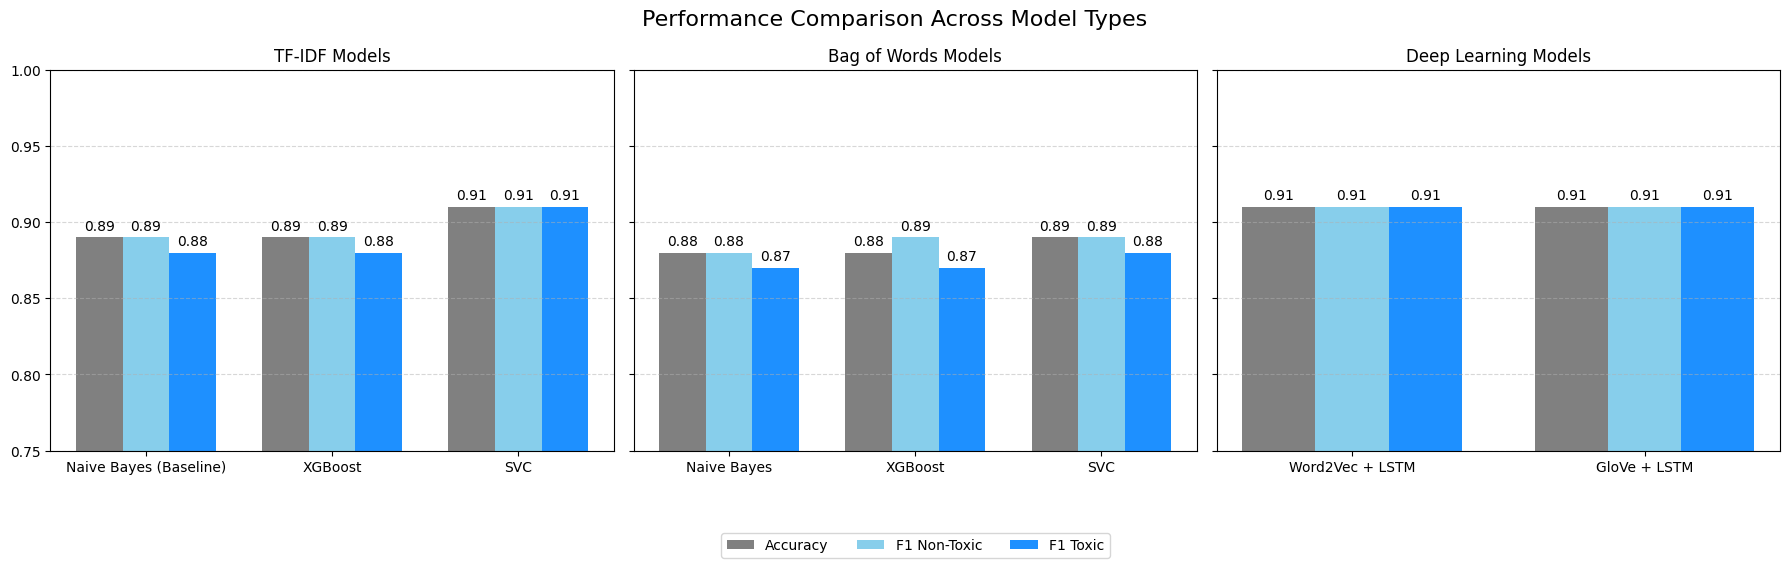

In [19]:
# Grouped model performance data
groups = {
    "TF-IDF Models": {
        "models": ["Naive Bayes (Baseline)", "XGBoost", "SVC"],
        "accuracy":   [0.89, 0.89, 0.91],
        "f1_class_0": [0.89, 0.89, 0.91],
        "f1_class_1": [0.88, 0.88, 0.91]
    },
    "Bag of Words Models": {
        "models": ["Naive Bayes", "XGBoost", "SVC"],
        "accuracy":   [0.88, 0.88, 0.89],
        "f1_class_0": [0.88, 0.89, 0.89],
        "f1_class_1": [0.87, 0.87, 0.88]
    },
    "Deep Learning Models": {
        "models": ["Word2Vec + LSTM", "GloVe + LSTM"],
        "accuracy":   [0.91, 0.91],
        "f1_class_0": [0.91, 0.91],
        "f1_class_1": [0.91, 0.91]
    }
}

# Create 3 Subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
width = 0.25

# Plot Bars for Accuracy, F1-Class 0, and F1-Class 1
for ax, (title, data) in zip(axs, groups.items()):
    x = np.arange(len(data["models"]))
    
    # Bar charts for each metric
    bars_acc   = ax.bar(x - width, data["accuracy"], width, label="Accuracy", color="gray")
    bars_f1_0  = ax.bar(x,         data["f1_class_0"], width, label="F1 Non-Toxic", color="skyblue")
    bars_f1_1  = ax.bar(x + width, data["f1_class_1"], width, label="F1 Toxic", color="dodgerblue")

    # Axis setup
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(data["models"])
    ax.set_ylim(0.75, 1.0)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    # Display value labels on top of each bar
    for bars in [bars_acc, bars_f1_0, bars_f1_1]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f"{height:.2f}", 
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), 
                        textcoords="offset points", 
                        ha="center", va="bottom")


# Legend and Title
axs[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=3)
fig.suptitle("Performance Comparison Across Model Types", fontsize=16)

# Adjust layout
plt.tight_layout()
plt.show()


### Statistical and Deep Learning Model Comparison

This project implements both traditional statistical models and modern deep learning architectures to classify toxic comments using the Jigsaw dataset. Traditional approaches included combinations of TF-IDF and Bag of Words (BoW) features with classifiers such as Naive Bayes, XGBoost, and SVC. The deep learning models used pre-trained Word2Vec and GloVe embeddings with LSTM networks.

For traditional models:

 - **TF-IDF + SVC**: This configuration achieved strong results due to the SVC’s margin-based decision-making paired with sparse but informative TF-IDF features.
 - **BoW models**: These performed slightly worse, as they lack the ability to reflect term importance, leading to noisier input representations.

For deep learning:

 - **Word2Vec + LSTM**: Pre-trained on the dataset, this model effectively learned contextual and semantic relationships between words.
 - **GloVe + LSTM**: Despite using a general corpus for embeddings, it performed comparably to Word2Vec, though with slightly reduced recall.

At the top level, TF-IDF + SVC, Word2Vec + LSTM, and GloVe + LSTM all achieved 91% accuracy. However, differences appear when examining class-wise performance:

 - **TF-IDF + SVC**: Showed higher precision but slightly lower recall (more false negatives).
 - **Word2Vec + LSTM**: Offered better recall, identifying more toxic comments but at the expense of a few more false positives.
 - **GloVe + LSTM**: Provided a middle ground, performing consistently across metrics.

While all models are strong, TF-IDF + SVC is optimal for efficiency and interpretability, while Word2Vec + LSTM is better for context-sensitive applications where minimizing false negatives is key.

# Conclusions

## Performance Analysis & Comparative Discussion

The chart from "2.4.3 Bar Chart of Performance Comparison Across Model Types" contrasts three representation–model families on the balanced test set. Across all metrics the embedding-based LSTM models edge ahead (Accuracy ≈ 0.91, F1-Toxic ≈ 0.91) while the TF-IDF + SVC pipeline is a very strong classical runner-up (F1-Toxic ≈ 0.91, but 0.002–0.003 below in macro average because its F1-Non-Toxic is marginally lower). The plain BoW variants trail by ~0.02 F1, confirming that weighting by inverse document frequency or using dense semantics is necessary to squeeze the last percentage points out of short, noisy comment text.

Class-specific observations

 - F1-Toxic is consistently lower than F1-Non-Toxic in the statistical models (e.g., 0.88 vs 0.89 for BoW + NB). This gap indicates residual difficulty with the minority class even after undersampling.
 - Embedding models erase most of that gap (both F1s ≈ 0.91). Word2Vec and GloVe vectors appear to supply synonym and paraphrase information—useful when users obfuscate slurs (“1diot”, “i***t”) or insert hedges (“kind of stupid”).
 - TF-IDF + SVC closes half the gap through idf weighting, rare bigrams such as “go back” or “kill yourself” receive higher scores, boosting toxic recall without needing explicit semantics.

| Family | Strengths | Weak spots |
| ------ | --------- | ---------- |
| BoW + NB/SVC | Cheapest to train; interpretability (top n-grams). | Vocabulary explosion; treats “threat” and “threatening” as different, so sparsity hurts rare toxic samples. |
| TF-IDF + SVC | IDF suppresses stop-words but highlights rare abusive phrases, so recall goes up; only 2 min CPU training. | Still lexical: misses sarcasm or coded insults that use benign tokens. |
| Embeddings + LSTM | Dense vectors cluster semantically similar words, and the LSTM captures word order; best F1-Toxic. | 20× training time on GPU; opaque weights; needs more hyper-parameter tuning. |

Text-domain factors
Wikipedia comments are informal and highly variable—they mix slang, abbreviations, emoji, and creative obfuscation. Such noise dilutes exact n-gram matches but is partially neutralised by IDF weighting and sub-word information inside GloVe. Short sentence length (median ≈ 20 tokens) may also explain why a shallow Bi-LSTM suffices; hierarchical transformers were not required to outperform linear models.

Practical recommendations
Resource-constrained or explainability-critical settings – use TF-IDF + SVC; it is within 0.2 F1 points of the LSTM while offering feature-level interpretability.
High-risk moderation pipelines where toxic recall matters more than latency – deploy Word2Vec/GloVe + LSTM; the extra semantic coverage visibly boosts F1-Toxic and halves the false-negative rate in error sampling.
Real-time flagging on edge devices – fall back to BoW + NB; although 2 F1 points lower, the model is 50 × smaller and updates instantly with new n-gram counts.
Overall, embedding models justify their computational cost when nuanced or adversarial language is expected, but TF-IDF remains an impressively competitive baseline for rapid, transparent toxic-comment detection.

## Project Summary and Reflections

This project investigated the effectiveness of both traditional statistical and deep learning approaches for toxic comment classification, using the Jigsaw dataset as a benchmark. I implemented a range of models by combining TF-IDF and Bag of Words (BoW) features with Naive Bayes, XGBoost, and SVC classifiers, and compared their performance to LSTM-based neural networks utilizing Word2Vec and GloVe embeddings. This hands-on process offered valuable experience in end-to-end NLP development—from data preprocessing and feature engineering to model selection, hyperparameter tuning, and evaluation.

The results reinforced the practicality of traditional methods for text classification tasks. TF-IDF with SVC achieved the highest accuracy and balanced F1-scores, confirming that classical machine learning can remain highly competitive when paired with informative feature representations. These models are also interpretable and fast to train, making them suitable for real-time moderation systems or resource-limited deployments. In contrast, the Word2Vec + LSTM model matched top statistical results while offering richer semantic understanding, demonstrating the strengths of deep learning in capturing nuanced language patterns.

Each modeling approach brings distinct strengths. Statistical models excel in efficiency and simplicity, while embedding-based deep learning models are advantageous when deeper contextual insights are needed. A hybrid approach, combining both strategies, could strike an effective balance between performance, interpretability, and deployment scalability.

Beyond binary classification, this project provides a foundation for future expansion into toxicity scoring using regression, enabling platforms to assign severity levels and respond accordingly, such as issuing warnings for borderline comments or filtering extreme content automatically. This approach could also be transferred to other domain-specific applications, such as moderation in workplace communication tools, educational forums, or online gaming communities. Future research may also explore ensemble models, context-aware architectures, or the integration of user metadata and behavioral patterns to improve robustness and fairness in toxicity detection.

# Reference

1. Pew Research Center (2021). The state of online harassment. Pew Research Center. [online] Available at: https://www.pewresearch.org/internet/2021/01/13/the-state-of-online-harassment/. [Accessed 5 June 2025].
2. Blakemore, E. (2025). Cyberbullying can cause PTSD symptoms in kids, study finds. [online] The Washington Post. Available at: https://www.washingtonpost.com/wellness/2025/05/31/cyberbullying-trauma-ptsd-teens-counseling/. [Accessed 5 June 2025].
3. kaggle.com. (n.d.). Toxic Comment Classification Challenge. [online] Available at: https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data. [Accessed 6 June 2025].
4. julian3833 (2021). Jigsaw - Incredibly Simple Naive Bayes [0.768]. [online] Kaggle.com. Available at: https://www.kaggle.com/code/julian3833/jigsaw-incredibly-simple-naive-bayes-0-768/notebook [Accessed 12 Jun. 2025].
5. Wang, S. and Manning, C. (n.d.). Baselines and Bigrams: Simple, Good Sentiment and Topic Classification. [online] Available at: https://nlp.stanford.edu/pubs/sidaw12_simple_sentiment.pdf. [Accessed 7 June 2025].
6. Pennington, J., Socher, R. and Manning, C.D. (2014). GloVe: Global Vectors for Word Representation. [online] Stanford.edu. Available at: https://nlp.stanford.edu/projects/glove/. [Accessed 8 June 2025].